# 06 · Stability across years: the 2011–2023 walk-forward

**In the story** (notebook 00, §§4.2–4.3, §5, §6 and Figure 1): repeated out of sample over 2011–2023, with monthly fits on the preceding 12 months, the correction usually helps. Its median yearly Gain over 2015–2023 is 0.12 for calls and 0.10 for puts. Its advantage disappears in 2022–2023 as implied volatility became less responsive to index moves. This notebook also examines the spot–volatility slope and the fixed scaling's failure on SPX in 2022–2023.

The project asks how stable the minimum-variance delta's advantage is across years. The pre-declared walk-forward (`analysis_plan.md` §14, item 2) answers that question.

Coefficients are refitted monthly on trailing 12-, 36- and 60-month windows. The windows are compared on their common test months, 2015-01 to 2023-12; the 12- and 36-month windows also start earlier. Each year gets its own session-block bootstrap.

2015–2020 had already been used for fitting or evaluation, so the clean held-out years are 2011–2013 and 2021–2023 (`results/year_ledger.csv`).

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
g = pd.read_csv(R / "walkforward/gains_by_year.csv")
t = g[(g.rule == "R2") & (g.base == "R1")].pivot_table(index=["year", "status"], columns=["window", "cp"], values="gain")
t.round(3)

window                                  12            36            60       
cp                                       C      P      C      P      C      P
year status                                                                  
2011 untouched                       0.242  0.152    NaN    NaN    NaN    NaN
2012 untouched                       0.031  0.092    NaN    NaN    NaN    NaN
2013 untouched                       0.151  0.155  0.135  0.154    NaN    NaN
2014 fit-only (2019 dry run)         0.188  0.207  0.201  0.218    NaN    NaN
2015 fit-only                        0.253  0.276  0.256  0.272  0.255  0.287
2016 fit-only                        0.181  0.152  0.186  0.168  0.175  0.171
2017 fit-only                        0.124  0.052  0.116  0.020  0.114  0.024
2018 evaluated (rehearsal)           0.033  0.056  0.133  0.188  0.141  0.192
2019 evaluated (rehearsal, dry run)  0.116  0.100  0.159  0.158  0.161  0.160
2020 evaluated (unblinding)          0.185  0.120  0.178  0.142  0.176  0.144
2021 untouched                       0.154  0.161  0.157  0.173  0.157  0.173
2022 untouched                       0.002 -0.058 -0.168 -0.232 -0.157 -0.229
2023 untouched                       0.002 -0.014 -0.025 -0.021 -0.059 -0.070

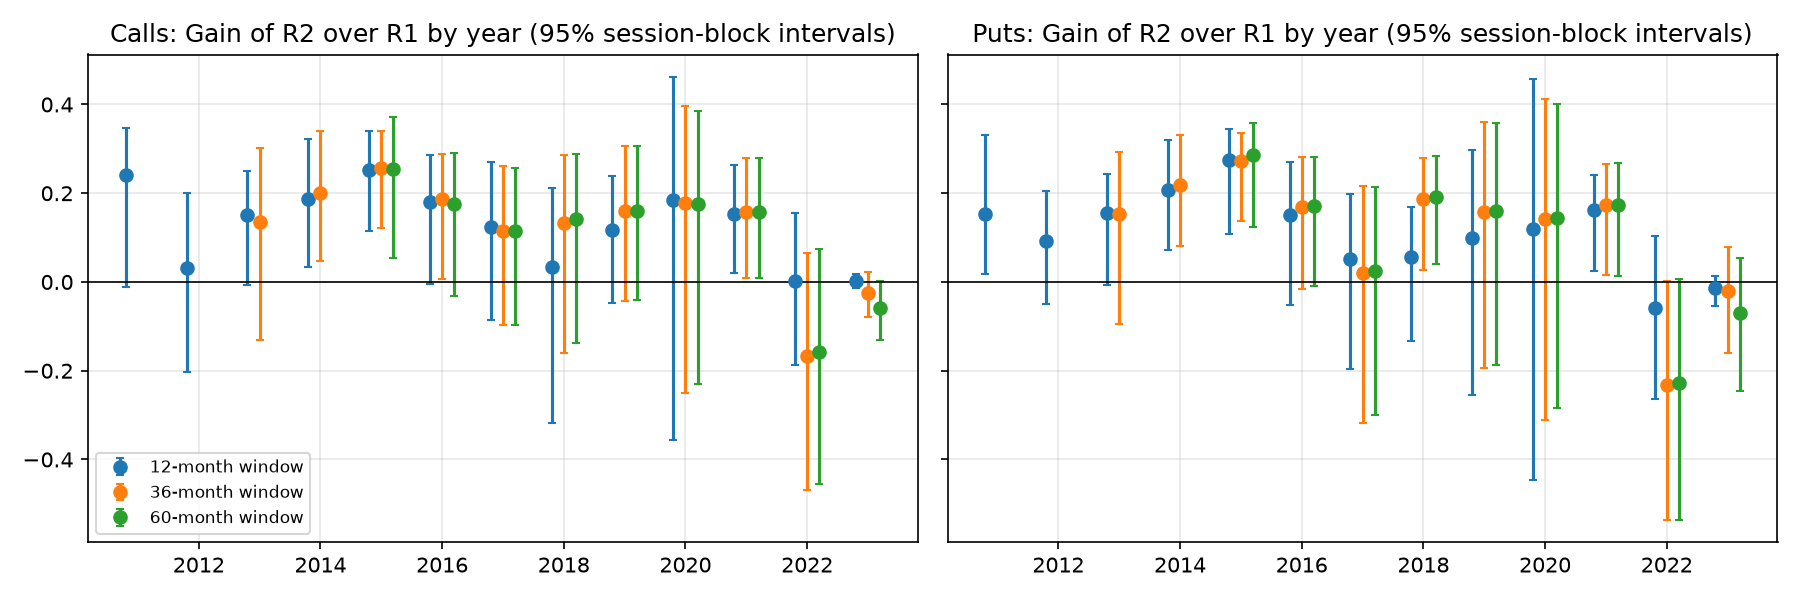

In [3]:
from IPython.display import Image
Image(filename=str(R / "figures/walkforward_by_year.png"))

In [4]:
pd.read_csv(R / "walkforward/median_yearly_gain.csv").round(3)

,window,cp,base,median_yearly_gain
0,12,C,R1,0.124
1,12,C,R3,0.036
2,12,C,R4,0.031
3,12,P,R1,0.100
4,12,P,R3,0.054
5,12,P,R4,0.039
6,36,C,R1,0.157
7,36,C,R3,0.032
8,36,C,R4,0.035
9,36,P,R1,0.158


In [5]:
g[(g.rule == "R2") & g.base.isin(["R1", "R4"]) & (g.year >= 2021)][["window", "year", "cp", "base", "gain", "lo", "hi"]].round(3)

,window,year,cp,base,gain,lo,hi
120,12,2021,C,R1,0.154,0.020,0.264
122,12,2021,C,R4,0.031,0.007,0.056
126,12,2021,P,R1,0.161,0.025,0.242
128,12,2021,P,R4,0.071,0.012,0.118
132,12,2022,C,R1,0.002,-0.186,0.155
134,12,2022,C,R4,-0.008,-0.046,0.033
138,12,2022,P,R1,-0.058,-0.263,0.103
140,12,2022,P,R4,-0.021,-0.071,0.027
144,12,2023,C,R1,0.002,-0.014,0.017
146,12,2023,C,R4,-0.002,-0.007,0.001


## Significant years, and the scaling rules year by year

Counts cover the 26 call-or-put years of 2011–2023, with the 12-month window. Significance is pointwise (each year's own 95% interval), not adjusted for multiple comparisons.

In [6]:
w12 = g[g.window == 12]
for base, name in (("R1", "Black–Scholes (R1)"), ("R3", "the fixed 0.9/1.1 scaling (R3)"), ("R4", "the fitted scaling (R4)")):
    z = w12[(w12.rule == "R2") & (w12.base == base)]
    win, lose = z[z.lo > 0], z[z.hi < 0]
    print(f"R2 against {name}: significantly better in {len(win)} of {len(z)}, significantly worse in {len(lose)}",
          list(zip(lose.year, lose.cp)) if len(lose) else "")
med = w12[w12.base == "R1"].query("2015 <= year <= 2023").groupby(["rule", "cp"]).gain.median().unstack()
print("median yearly Gain over Black–Scholes, 2015–2023:"); med.round(3)

R2 against Black–Scholes (R1): significantly better in 7 of 26, significantly worse in 0 
R2 against the fixed 0.9/1.1 scaling (R3): significantly better in 14 of 26, significantly worse in 2 [(2018, 'C'), (2018, 'P')]
R2 against the fitted scaling (R4): significantly better in 12 of 26, significantly worse in 0 
median yearly Gain over Black–Scholes, 2015–2023:


cp,C,P
rule,,
R2,0.124,0.100
R3,0.125,0.099
R4,0.120,0.060


**Reading.** Through 2021 the advantage is consistent. With the 12-month window, the Gain over Black–Scholes is positive every year, mostly 0.10–0.25. It is significantly positive in 7 of 26 call-or-put years and significantly negative in none. In 2021, a clean year, it is significant for both calls and puts, and the minimum-variance delta (R2) also beats the fitted scaling rule.

In 2022–2023 the advantage disappears. With the 12-month window it is about 0, with tight intervals in 2023. With the longer windows it turns negative in 2022 (−0.16 to −0.23): for puts, R2 is significantly worse than the fitted scaling rule.

R2 beats the fixed 0.9/1.1 scaling significantly in 14 of 26 call-or-put years and loses in two, both in 2018; it beats the fitted scaling in 12 and never loses. Yet the fixed scaling's median Gain over Black–Scholes (0.125 / 0.099) matches R2's (0.124 / 0.100). The fixed scaling wins clearly in 2018 and fails in 2022 (−0.14 to −0.18) and 2023 (−0.06 to −0.14), when the volatility response it was read from had weakened. Notebook 08 compares R2 with the other challengers.

In [7]:
pd.read_csv(R / "walkforward/spot_vol_slope.csv").round(3)

,year,sessions,vol_points_per_1pct_fall,corr
0,2011,242,0.446,-0.651
1,2012,246,0.247,-0.376
2,2013,251,0.353,-0.451
3,2014,247,0.329,-0.531
4,2015,252,0.387,-0.622
5,2016,250,0.286,-0.469
6,2017,249,0.196,-0.235
7,2018,251,0.445,-0.534
8,2019,233,0.384,-0.556
9,2020,247,0.353,-0.388


The minimum-variance correction works through the co-movement of implied volatility and the index. The table measures it each year for near-the-money options (|δ| 0.4–0.6) 20–60 days from expiry. It reports the slope of each session's median change in implied volatility on the index return, in volatility points per 1% index fall (`scripts/spot_vol_slope.py`).

The slope collapsed. It was 0.20–0.55 vol points per 1% fall in 2011–2021 (0.25–0.55 outside 2017; 0.55 in 2021), and 0.13 in both 2022 and 2023.

The fitted coefficients were therefore too large: they had learned a stronger relation than the market then delivered. Longer windows remember more of it, and suffered more. Notebook 09 gives an exact identity for each monthly fit: the Gain depends on the fitted level of the correction against the level that month rewarded, and a level more than twice too large loses to Black–Scholes.

2017 provides an earlier analogue. That earlier low-slope year (0.20) had the smallest put Gain before 2022 (0.05).

This is a descriptive reading. A model validator would take it as the case for monitoring the spot–volatility slope alongside the hedge.

## The boosted challenger in the walk-forward

R8, the LightGBM correction on market features boosted from R2, is retuned once on 2015–2016, with validation pairs ending before 2017. It is then refitted monthly on the 12-month window from 2017 on. Each row is its relative Gain over R2.

In [8]:
w = pd.read_csv(R / "walkforward/r8_by_year.csv")
w[w.rule == "R8"][["year", "cp", "gain", "lo", "hi"]].round(3)

,year,cp,gain,lo,hi
0,2017,C,-0.040,-0.142,0.040
2,2017,P,-0.059,-0.130,0.015
4,2018,C,-0.040,-0.151,0.058
6,2018,P,-0.020,-0.170,0.048
8,2019,C,0.007,-0.027,0.040
10,2019,P,0.051,-0.006,0.108
12,2020,C,0.075,-0.025,0.159
14,2020,P,-1.984,-2.986,-0.030
16,2021,C,-0.001,-0.010,0.008
18,2021,P,0.008,-0.010,0.024


**Reading.** The tuning chose a minimal model: 51 trees, a learning rate of 0.01, 4 leaves. In most years R8 is within a few percent of R2.

2020 puts are the exception. The crash pushed the features far outside their training range, and even this small correction roughly tripled R2's squared error (relative Gain −1.98). The same failure appears in the 2020 test (notebook 05).